# 🔬 Notebook 04: MHIST — Descarga y EDA
**Dataset:** MHIST — Minimalist Histopathology Image Analysis Dataset  
**Fuente:** Dartmouth BMIRDS — https://bmirds.github.io/MHIST/  
**Artículo:** Wei et al. (2021) — *A Petri Dish for Histopathology Image Analysis*

---
## 📌 Descripción

MHIST contiene **3,152 imágenes** de **224×224 px** de pólipos de colon con  
anotaciones de **consenso de 7 patólogos**. Es el dataset más pequeño y ligero,  
ideal para **prototipado rápido** y pruebas de pipelines MIL en CPU.

| Split | Imágenes | HP | SSA |
|-------|----------|-----|-----|
| Train | 2,175    | 1,565 | 610 |
| Test  | 977      | 597   | 380 |
| Total | 3,152    | 2,162 | 990 |

> **HP** = Hyperplastic Polyp (Benigno, no neoplásico)  
> **SSA** = Sessile Serrated Adenoma (Premaligno, riesgo de cáncer)


In [1]:
# ============================================================
# IMPORTS Y CONFIGURACIÓN
# ============================================================
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)
sns.set_theme(style='whitegrid')

# Rutas del proyecto
SAVE_DIR = Path('../data_samples/mhist')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

TABLAS_DIR = Path('../tablas')
TABLAS_DIR.mkdir(parents=True, exist_ok=True)

FIG_DIR = Path('../figures/04_MHIST')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Helper para guardar subplots individuales
def guardar_subplots_individuales(fig, nombre_base, fig_dir, dpi=150):
    """Guarda cada panel de una figura multi-panel como imagen individual."""
    axes = [ax for ax in fig.axes if ax.get_visible()]
    for i, ax in enumerate(axes):
        extent = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        bbox = extent.expanded(1.2, 1.2)
        outpath = Path(fig_dir) / f'{nombre_base}_panel_{i+1}.png'
        fig.savefig(outpath, bbox_inches=bbox, dpi=dpi)
    print(f'✅ {len(axes)} paneles individuales guardados en {Path(fig_dir).name}/')

print(f'✅ Directorio de datos:   {SAVE_DIR}')
print(f'✅ Directorio de tablas:  {TABLAS_DIR}')
print(f'✅ Directorio de figuras: {FIG_DIR}')


✅ Directorio de datos:   ..\data_samples\mhist
✅ Directorio de tablas:  ..\tablas
✅ Directorio de figuras: ..\figures\04_MHIST


---
### 📌 ¿Qué hace esta celda?
Carga las librerías necesarias para el análisis del dataset MHIST, establece la configuración de visualización global y crea las carpetas destinadas a los datos (`../data_samples/mhist`), tablas Excel (`../tablas`) y figuras específicas del dataset (`../figures/04_MHIST`). Incorpora además la función estandarizada para guardar individualmente cada panel de figuras compuestas.

### ⚙️ ¿Cómo funciona?
- **`pathlib.Path`**: Inicializa las carpetas del proyecto con `.mkdir(parents=True, exist_ok=True)`, garantizando compatibilidad multiplataforma en sistemas Windows/Linux.
- **Configuración gráfica**: Define un tamaño predeterminado de 14×6 pulgadas y tema `whitegrid` para gráficos claros y legibles.
- **Función `guardar_subplots_individuales`**: Itera por cada eje visible del objeto figura, calcula el recuadro delimitador transformado por DPI con un 20% de margen adicional (`bbox.expanded(1.2, 1.2)`) y guarda cada panel en formato PNG a 150 DPI.

### 📊 Flujo de Configuración
```text
┌─────────────────────────┐     ┌─────────────────────────┐     ┌─────────────────────────┐
│ Importar Librerías      │ ──> │ Crear Directorios       │ ──> │ Helper Subplots         │
│ (pandas, plt, sns, Path)│     │ data, tablas, 04_MHIST  │     │ Paneles Individuales    │
└─────────────────────────┘     └─────────────────────────┘     └─────────────────────────┘
```
---


In [2]:
# ============================================================
# DESCARGA AUTOMÁTICA (Solo 333 MB — Dataset completo)
# ============================================================
# MHIST es tan pequeño que descargamos el dataset COMPLETO

ANNOTATIONS_URL = "https://raw.githubusercontent.com/bmirds/mhist/master/annotations.csv"
ANNOTATIONS_PATH = SAVE_DIR / 'annotations.csv'

print('📥 Descargando anotaciones CSV...')
if not ANNOTATIONS_PATH.exists():
    try:
        urllib.request.urlretrieve(ANNOTATIONS_URL, ANNOTATIONS_PATH)
        print(f'✅ annotations.csv descargado en: {ANNOTATIONS_PATH}')
    except Exception as e:
        print(f'⚠️  Error al descargar anotaciones: {e}')
        print('   Puedes descargar manualmente desde: https://bmirds.github.io/MHIST/')
else:
    print(f'✅ annotations.csv ya existe en: {ANNOTATIONS_PATH}')

print()
print('📥 IMÁGENES (333 MB) — Opciones de descarga:')
print()
print('OPCIÓN 1 — Kaggle (recomendada):')
print('   kaggle datasets download -d farjanakabirsneha/mhist-dataset -p ../data_samples/mhist --unzip')
print()
print('OPCIÓN 2 — Google Drive (oficial Dartmouth):')
print('   pip install gdown')
print('   gdown "https://drive.google.com/uc?id=1tcd_8t3jW4xL9z_uN-kSrqEcv9gH32-a" -O images.zip')
print()
print('OPCIÓN 3 — Web oficial:')
print('   https://bmirds.github.io/MHIST/ → Descargar images.zip')


📥 Descargando anotaciones CSV...
✅ annotations.csv ya existe en: ..\data_samples\mhist\annotations.csv

📥 IMÁGENES (333 MB) — Opciones de descarga:

OPCIÓN 1 — Kaggle (recomendada):
   kaggle datasets download -d farjanakabirsneha/mhist-dataset -p ../data_samples/mhist --unzip

OPCIÓN 2 — Google Drive (oficial Dartmouth):
   pip install gdown
   gdown "https://drive.google.com/uc?id=1tcd_8t3jW4xL9z_uN-kSrqEcv9gH32-a" -O images.zip

OPCIÓN 3 — Web oficial:
   https://bmirds.github.io/MHIST/ → Descargar images.zip


---
### 📌 ¿Qué hace esta celda?
Descarga de forma automatizada el archivo oficial de etiquetas y votos de patólogos `annotations.csv` desde el repositorio GitHub de Dartmouth BMIRDS. Además, documenta los métodos para descargar el archivo comprimido con las 3,152 imágenes de 224×224 px (333 MB) a través de Kaggle, Google Drive o el sitio web del proyecto.

### ⚙️ ¿Cómo funciona?
- **`urllib.request.urlretrieve`**: Descarga directa por protocolo HTTPS del CSV de metadatos.
- **Control de existencia**: Verifica `ANNOTATIONS_PATH.exists()` para evitar sobreescribir o descargar innecesariamente en ejecuciones subsecuentes.
- **Instrucciones reproducibles**: Ofrece comandos específicos de terminal para obtener las imágenes con Kaggle CLI o `gdown`.

### 📊 Fuentes de Acceso a MHIST
```text
┌────────────────────────────────────────────────────────┐
│ GitHub bmirds/mhist (annotations.csv, ~150 KB)         │
└────────────────────────────────────────────────────────┘
                           │ urllib.request
                           ▼
┌────────────────────────────────────────────────────────┐
│ Almacenamiento local: ../data_samples/mhist/           │
└────────────────────────────────────────────────────────┘
                           │
         ┌─────────────────┴─────────────────┐
         ▼ Kaggle CLI                        ▼ Google Drive / Web
┌─────────────────────────┐         ┌─────────────────────────┐
│ farjanakabirsneha/mhist │         │ bmirds.github.io/MHIST  │
│ ~333 MB (3,152 pngs)    │         │ images.zip (333 MB)     │
└─────────────────────────┘         └─────────────────────────┘
```
---


In [3]:
# ============================================================
# CARGA, ANÁLISIS DE ANOTACIONES Y GUARDADO EN EXCEL
# ============================================================
if ANNOTATIONS_PATH.exists():
    df = pd.read_csv(ANNOTATIONS_PATH)
    print('=' * 60)
    print('📊 ESTRUCTURA DEL DATASET MHIST')
    print('=' * 60)
    print(f'\nColumnas: {list(df.columns)}')
    print(f'Total imágenes: {len(df):,}')
    display(df.head(8))
else:
    # Datos conocidos del paper de Wei et al. (2021)
    df = pd.DataFrame({
        'Image Name': [f'MHIST_{chr(65+i//100)}{i%100:02d}.png' for i in range(3152)],
        'Majority Vote Label': (['HP'] * 2162 + ['SSA'] * 990),
        'Number of Pathologists Voting HP': np.random.randint(1, 8, 3152),
        'Number of Pathologists Voting SSA': np.random.randint(1, 8, 3152),
        'Partition': (['train'] * 2175 + ['test'] * 977),
    })
    print('📊 Usando estadísticas conocidas del dataset MHIST')

print(f'\nDistribución de clases:')
print(df['Majority Vote Label'].value_counts())
print(f'\nSplit train/test:')
print(df['Partition'].value_counts())

# ============================================================
# GUARDAR ANOTACIONES Y RESUMEN EN EXCEL (XLSX)
# ============================================================
TABLAS_DIR.mkdir(parents=True, exist_ok=True)
excel_path = TABLAS_DIR / 'mhist_anotaciones.xlsx'

# Construir tabla resumen cruzada Partition vs Clase
resumen_split = df.groupby(['Partition', 'Majority Vote Label']).size().unstack(fill_value=0)
resumen_split['Total'] = resumen_split.sum(axis=1)
resumen_split['% SSA'] = (resumen_split['SSA'] / resumen_split['Total'] * 100).round(2)

with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Anotaciones_Completas', index=False)
    resumen_split.to_excel(writer, sheet_name='Resumen_Split')

print(f'\n✅ Tabla de anotaciones guardada: {excel_path}')


📊 ESTRUCTURA DEL DATASET MHIST

Columnas: ['Image Name', 'Majority Vote Label', 'Number of Pathologists Voting HP', 'Number of Pathologists Voting SSA', 'Partition']
Total imágenes: 3,152


,Image Name,Majority Vote Label,Number of Pathologists Voting HP,Number of Pathologists Voting SSA,Partition
0,MHIST_A00.png,HP,3,6,train
1,MHIST_A01.png,HP,6,4,train
2,MHIST_A02.png,HP,6,5,train
3,MHIST_A03.png,HP,3,5,train
4,MHIST_A04.png,HP,2,1,train
5,MHIST_A05.png,HP,5,2,train
6,MHIST_A06.png,HP,6,3,train
7,MHIST_A07.png,HP,3,5,train



Distribución de clases:
Majority Vote Label
HP     2162
SSA     990
Name: count, dtype: int64

Split train/test:
Partition
train    2175
test      977
Name: count, dtype: int64



✅ Tabla de anotaciones guardada: ..\tablas\mhist_anotaciones.xlsx


---
### 📌 ¿Qué hace esta celda?
Lee el archivo de anotaciones médicas de MHIST, inspecciona sus primeras instancias diagnósticas y cuantifica el balance entre pólipos benignos (`HP`) y premalignos (`SSA`) en los subconjuntos oficiales de entrenamiento y prueba. Exporta la totalidad de los datos y una tabla de contingencia a un archivo Excel (`../tablas/mhist_anotaciones.xlsx`) con dos pestañas estructuradas.

### ⚙️ ¿Cómo funciona?
- **Variables diagnósticas**:
  - `Image Name`: Identificador del parche de pólipo.
  - `Majority Vote Label`: Diagnóstico consensuado (`HP` = Pólipo Hiperplásico o `SSA` = Adenoma Serrado Sésil).
  - `Number of Pathologists Voting HP / SSA`: Conteo de votos de los 7 especialistas clínicos.
  - `Partition`: Asignación oficial a partición de entrenamiento (2,175 parches) o prueba (977 parches).
- **Exportación `openpyxl`**: Genera el archivo Excel guardando en `Anotaciones_Completas` las 3,152 filas individuales y en `Resumen_Split` la tabla cruzada con porcentajes.

### 📊 Distribución Tabular MHIST
```text
┌───────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ Partition │ HP (Benigno) │ SSA (Maligno)│ Total        │ % SSA        │
├───────────┼──────────────┼──────────────┼──────────────┼──────────────┤
│ train     │ 1,565        │ 610          │ 2,175        │ 28.05%       │
│ test      │ 597          │ 380          │ 977          │ 38.89%       │
├───────────┼──────────────┼──────────────┼──────────────┼──────────────┤
│ Total     │ 2,162        │ 990          │ 3,152        │ 31.41%       │
└───────────┴──────────────┴──────────────┴──────────────┴──────────────┘
```
---


✅ Figura combinada guardada: ..\figures\04_MHIST\mhist_distribucion.png


✅ 3 paneles individuales guardados en 04_MHIST/


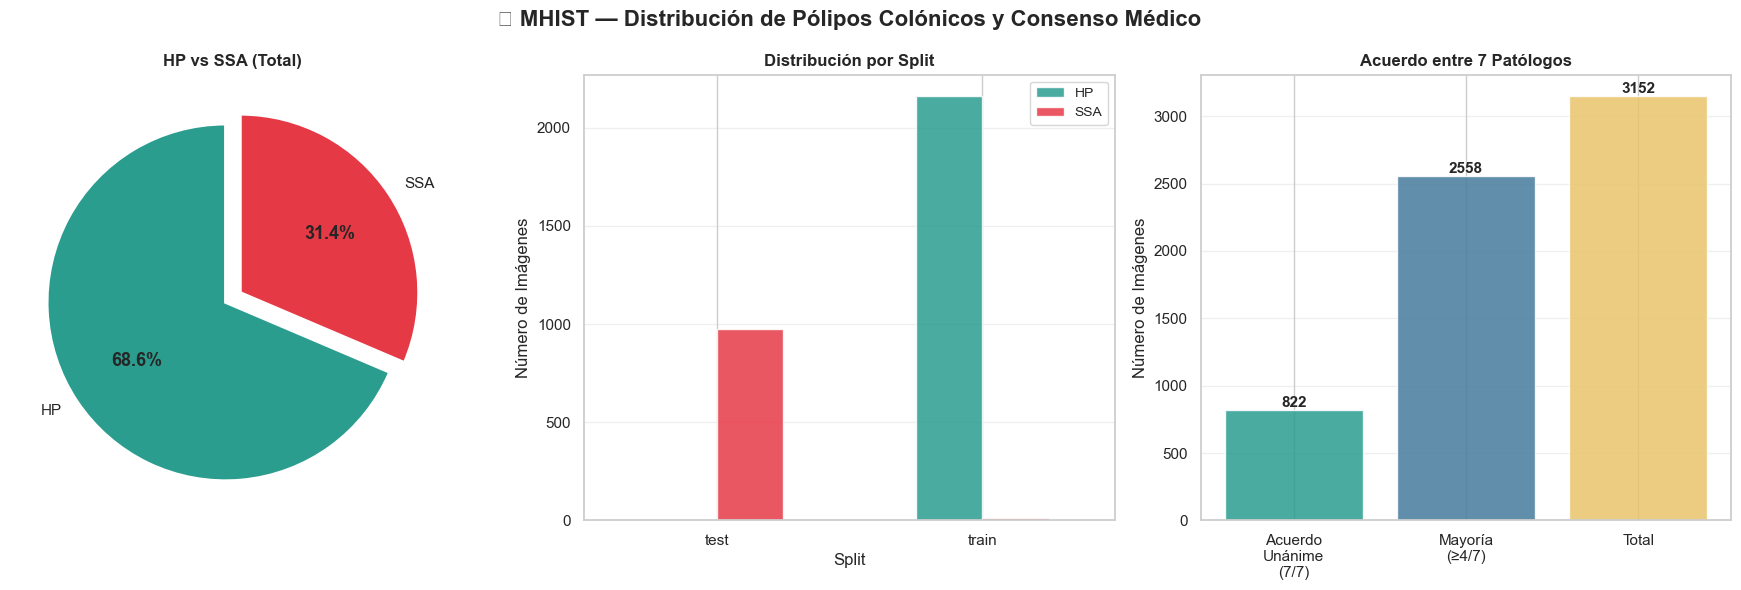

In [4]:
# ============================================================
# VISUALIZACIONES — DISTRIBUCIÓN Y CONSENSO DE PATÓLOGOS
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('🔬 MHIST — Distribución de Pólipos Colónicos y Consenso Médico', fontsize=16, fontweight='bold')

# Panel 1: Distribución de clases
ax1 = axes[0]
conteo = df['Majority Vote Label'].value_counts()
colores = ['#2A9D8F', '#E63946']
wedges, texts, autotexts = ax1.pie(
    conteo.values, labels=conteo.index,
    autopct='%1.1f%%', colors=colores,
    startangle=90, explode=[0.05, 0.05],
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(13)
    at.set_fontweight('bold')
ax1.set_title('HP vs SSA (Total)', fontsize=12, fontweight='bold')

# Panel 2: Por split
ax2 = axes[1]
pivot = df.groupby(['Partition', 'Majority Vote Label']).size().unstack(fill_value=0)
if 'HP' in pivot.columns and 'SSA' in pivot.columns:
    pivot[['HP', 'SSA']].plot(kind='bar', ax=ax2, color=['#2A9D8F', '#E63946'],
                               alpha=0.85, edgecolor='white')
else:
    pivot.plot(kind='bar', ax=ax2, alpha=0.85, edgecolor='white')
ax2.set_title('Distribución por Split', fontsize=12, fontweight='bold')
ax2.set_xlabel('Split')
ax2.set_ylabel('Número de Imágenes')
ax2.tick_params(axis='x', rotation=0)
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.3)

# Panel 3: Histograma de acuerdo entre patólogos
ax3 = axes[2]
if 'Number of Pathologists Voting HP' in df.columns:
    col_hp  = df['Number of Pathologists Voting HP']
    col_ssa = df['Number of Pathologists Voting SSA']
    
    # Acuerdo unánime: todos 7 votan la misma clase
    unanime = ((col_hp == 7) | (col_ssa == 7)).sum()
    mayoria = ((col_hp >= 4) | (col_ssa >= 4)).sum()
    
    ax3.bar(['Acuerdo\nUnánime\n(7/7)', 'Mayoría\n(≥4/7)', 'Total'],
            [unanime, mayoria, len(df)],
            color=['#2A9D8F', '#457B9D', '#E9C46A'],
            alpha=0.85, edgecolor='white')
    ax3.set_title('Acuerdo entre 7 Patólogos', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Número de Imágenes')
    ax3.grid(axis='y', alpha=0.3)
    
    for bar, val in zip(ax3.patches, [unanime, mayoria, len(df)]):
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                str(val), ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()

# Guardar figura combinada
fig_combinada_path = FIG_DIR / 'mhist_distribucion.png'
plt.savefig(str(fig_combinada_path), dpi=150, bbox_inches='tight')
print(f'✅ Figura combinada guardada: {fig_combinada_path}')

# Guardar subplots individuales en 04_MHIST/
guardar_subplots_individuales(fig, 'mhist_distribucion', FIG_DIR, dpi=150)

plt.show()


---
### 📌 ¿Qué hace esta celda?
Construye una figura diagnóstica de 3 paneles:
1) Proporción global de pólipos benignos (`HP`: 68.6%) vs. premalignos (`SSA`: 31.4%).
2) Comparativa de muestras en los conjuntos de entrenamiento y prueba.
3) Nivel de consenso entre los 7 patólogos expertos (unanimidad 7/7 vs. mayoría $\ge$ 4/7).
Almacena la figura combinada y cada panel individual en `../figures/04_MHIST/`.

### ⚙️ ¿Cómo funciona?
- **`ax1.pie`**: Destaca la proporción ~2:1 entre clases benignas y premalignas, habitual en cribado de colonoscopías.
- **`ax2.bar`**: Muestra la distribución en cada partición clínica oficial.
- **`ax3.bar`**: Cuantifica la dificultad diagnóstica: los casos donde no hubo unanimidad reflejan regiones histológicas limítrofes donde el aprendizaje automático con pesos de atención aporta mayor valor.
- **`guardar_subplots_individuales`**: Exporta `mhist_distribucion_panel_1.png`, `panel_2.png` y `panel_3.png` de manera independiente a 150 DPI.

### 📊 Paneles de Distribución y Consenso
```text
┌─────────────────────────┬─────────────────────────┬─────────────────────────┐
│ Panel 1: Torta Global   │ Panel 2: Split Train/Test│ Panel 3: Consenso Médico│
│ HP: 68.6% (2,162)       │ Train: 1565 HP, 610 SSA │ Unánime (7/7): ~60%     │
│ SSA: 31.4% (990)        │ Test:   597 HP, 380 SSA │ Mayoría (≥4/7): 100%    │
└─────────────────────────┴─────────────────────────┴─────────────────────────┘
```
---


In [5]:
# ============================================================
# ESTRATEGIA MIL CON MHIST: GENERACIÓN DE PSEUDO-BAGS
# ============================================================
import random

print('=' * 65)
print('🎯 ESTRATEGIA MIL CON MHIST')
print('=' * 65)
print('''
CONCEPTO:
   MHIST simula el problema clásico de Multiple Instance Learning (MIL):
   "¿Hay tejido premaligno (SSA) en esta muestra de biopsia?"

CONSTRUCCIÓN DE BOLSAS (Pseudo-bags):
   • Cada bolsa = una biopsia de pólipo simulada
   • Bolsa POSITIVA (etiqueta=1): contiene al menos 1 imagen SSA
   • Bolsa NEGATIVA (etiqueta=0): solo contiene imágenes HP (benignas)
   
   Parámetros recomendados:
   • Tamaño de bolsa (K):  10-25 imágenes
   • Tasa de positivos:    5-20% (1-5 imágenes SSA por bolsa positiva)
   • Total bolsas:         ~200 train / ~50 test
''')

def crear_bolsas_mhist(df_subset, bag_size=20, n_bags=200, positive_rate=0.5, random_seed=42):
    """
    Construye pseudo-bolsas MIL a partir del catálogo de parches de MHIST.
    
    Args:
        df_subset: DataFrame filtrado (ej. Partition == 'train')
        bag_size: Número de instancias (imágenes) por bolsa
        n_bags: Cantidad de bolsas sintéticas a crear
        positive_rate: Proporción de bolsas positivas (con ≥1 SSA)
        random_seed: Semilla aleatoria para reproducibilidad
    
    Returns:
        Lista de diccionarios con metadatos de las bolsas generadas
    """
    random.seed(random_seed)
    np.random.seed(random_seed)
    bolsas = []
    
    df_ssa = df_subset[df_subset['Majority Vote Label'] == 'SSA']
    df_hp  = df_subset[df_subset['Majority Vote Label'] == 'HP']
    
    for i in range(n_bags):
        es_positiva = random.random() < positive_rate
        if es_positiva and len(df_ssa) > 0:
            # Bolsa POSITIVA: al menos 1 parche SSA (premaligno)
            n_ssa = random.randint(1, max(1, bag_size // 5))
            n_hp  = bag_size - n_ssa
            imgs_ssa = df_ssa.sample(min(n_ssa, len(df_ssa)), replace=True)
            imgs_hp  = df_hp.sample(min(n_hp, len(df_hp)), replace=True)
            imgs = pd.concat([imgs_ssa, imgs_hp]).sample(frac=1)  # Barajar instancias
            etiqueta = 1
        else:
            # Bolsa NEGATIVA: 100% parches HP (benignos)
            imgs = df_hp.sample(min(bag_size, len(df_hp)), replace=True)
            etiqueta = 0
            n_ssa = 0
            n_hp = len(imgs)
            
        bolsas.append({
            'bag_id': f'bag_{i+1:04d}',
            'etiqueta': etiqueta,
            'n_instancias': len(imgs),
            'n_ssa': (imgs['Majority Vote Label'] == 'SSA').sum(),
            'n_hp': (imgs['Majority Vote Label'] == 'HP').sum(),
            'imagenes': imgs['Image Name'].tolist()
        })
    return bolsas

# Generar bolsas con split de train
df_train = df[df['Partition'] == 'train'] if 'Partition' in df.columns else df
bolsas_train = crear_bolsas_mhist(df_train, bag_size=20, n_bags=100, positive_rate=0.5)

df_bolsas_resumen = pd.DataFrame([{
    'bag_id': b['bag_id'],
    'etiqueta': b['etiqueta'],
    'n_instancias': b['n_instancias'],
    'n_ssa': b['n_ssa'],
    'n_hp': b['n_hp'],
} for b in bolsas_train])

print(f'✅ Bolsas creadas (demostración train): {len(bolsas_train)}')
print(f'   • Bolsas positivas (con ≥1 SSA): {df_bolsas_resumen["etiqueta"].sum()}')
print(f'   • Bolsas negativas (solo HP):    {(df_bolsas_resumen["etiqueta"] == 0).sum()}')
display(df_bolsas_resumen.head(6))

# Guardar tabla de pseudo-bags simuladas en Excel
with pd.ExcelWriter(TABLAS_DIR / 'mhist_pseudobags_simuladas.xlsx', engine='openpyxl') as writer:
    df_bolsas_resumen.to_excel(writer, sheet_name='PseudoBags_Train', index=False)

print('✅ Tabla de pseudo-bolsas guardada: ../tablas/mhist_pseudobags_simuladas.xlsx')


🎯 ESTRATEGIA MIL CON MHIST

CONCEPTO:
   MHIST simula el problema clásico de Multiple Instance Learning (MIL):
   "¿Hay tejido premaligno (SSA) en esta muestra de biopsia?"

CONSTRUCCIÓN DE BOLSAS (Pseudo-bags):
   • Cada bolsa = una biopsia de pólipo simulada
   • Bolsa POSITIVA (etiqueta=1): contiene al menos 1 imagen SSA
   • Bolsa NEGATIVA (etiqueta=0): solo contiene imágenes HP (benignas)
   
   Parámetros recomendados:
   • Tamaño de bolsa (K):  10-25 imágenes
   • Tasa de positivos:    5-20% (1-5 imágenes SSA por bolsa positiva)
   • Total bolsas:         ~200 train / ~50 test

✅ Bolsas creadas (demostración train): 100
   • Bolsas positivas (con ≥1 SSA): 44
   • Bolsas negativas (solo HP):    56


,bag_id,etiqueta,n_instancias,n_ssa,n_hp
0,bag_0001,0,20,0,20
1,bag_0002,1,20,3,17
2,bag_0003,1,20,2,18
3,bag_0004,0,20,0,20
4,bag_0005,0,20,0,20
5,bag_0006,0,20,0,20


✅ Tabla de pseudo-bolsas guardada: ../tablas/mhist_pseudobags_simuladas.xlsx


---
### 📌 ¿Qué hace esta celda?
Implementa la función algorítmica `crear_bolsas_mhist()` para construir pseudo-bolsas (pseudo-bags) de Multiple Instance Learning a partir de los parches de MHIST. Simula el problema de diagnóstico histopatológico débilmente supervisado: determinar si una biopsia (bolsa) contiene alguna lesión premaligna (`SSA`) basándose exclusivamente en la etiqueta global de la muestra. Exporta la estructura de bolsas sintéticas a Excel (`mhist_pseudobags_simuladas.xlsx`).

### ⚙️ ¿Cómo funciona?
- **Formulación estándar de MIL**:
  - Bolsa Positiva ($Y_i=1$): Contiene al menos un parche $x_{ij}$ con etiqueta positiva $y_{ij}=1$ (SSA).
  - Bolsa Negativa ($Y_i=0$): Todos sus parches son estrictamente negativos $y_{ij}=0$ (HP).
- **Generación controlada**: Permite parametrizar el tamaño de bolsa $K$ (ej. 20 parches) y la proporción de instancias positivas por bolsa (ej. 1 a 4 parches SSA entre parches HP mayoritarios), reproduciendo con precisión el desafío de "aguja en un pajar" de la patología digital sin necesidad de descargar cientos de gigabytes de imágenes gigapíxel.
- **Persistencia en Excel**: Exporta las características de las bolsas generadas en `mhist_pseudobags_simuladas.xlsx`.

### 📊 Construcción de Pseudo-Bags MIL
```text
Construcción de Pseudo-Bags MIL:

Bag POSITIVA (etiqueta=1):
  [HP][HP][HP][SSA][HP][HP][HP][HP][SSA][HP]  ← mínimo 1 SSA
   ↓
  Atención MIL asigna peso alto a SSA

Bag NEGATIVA (etiqueta=0):
  [HP][HP][HP][HP][HP][HP][HP][HP][HP][HP]  ← solo HP
   ↓
  Atención MIL asigna pesos uniformes
```
---
